**12 | Training-Only Class-Weighted Temporal CNN**

![Notebook 12 horizontal workflow](../images/12_workflow.svg)

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Objective:** Compare the same 1D-CNN with standard versus inverse-square-root class-weighted Cross-Entropy, using identical HARTH windows, participant split, random seed, architecture and training duration. Only the loss weighting changes. **This is an exploratory development ablation, not an independent Test or a matched Stage 9 benchmark.**

**01. Import the established study functions**

In [1]:
# ==================== 01. Import the established study functions ====================
# 1. Follow the documented import the established study functions procedure with the established dataset and checks.

# ------------------------------------------------------------
# 1) Python Standard Library
# ------------------------------------------------------------
import sys
from pathlib import Path
# ------------------------------------------------------------
# 2) Data and Machine Learning
# ------------------------------------------------------------
import numpy as np
import pandas as pd
# ------------------------------------------------------------
# 3) Visualisation and Display
# ------------------------------------------------------------
import matplotlib.pyplot as plt
# ------------------------------------------------------------
# 4) Deep Learning
# ------------------------------------------------------------
import torch
# ------------------------------------------------------------
# 3) Visualisation and Display
# ------------------------------------------------------------
from IPython.display import display
# ------------------------------------------------------------
# 2) Data and Machine Learning
# ------------------------------------------------------------
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Locate repository and register existing study modules.
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root == root.parent: raise RuntimeError("Open from the project directory.")
    root = root.parent
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))
# ------------------------------------------------------------
# 5) Project Utilities
# ------------------------------------------------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_window_cohort
from core.data_splitting import split_group_indices
from core.temporal_cnn import train_temporal_cnn, compute_training_class_weights
from core.ml_baselines import classification_class_report, evaluate_predictions_by_subject
from core.group_cross_validation import compare_models_by_subject
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

PyTorch: 2.12.1+cpu | CUDA: False


**02. Rebuild the exact bounded Stage 10/11 development cohort**

Use all 29 development participants, with up to 500 label-blind uniformly sampled eligible windows per person. Original Test IDs are explicitly excluded. Source labels outside 1–8 are removed after valid windows are formed.

In [2]:
# ==================== 02. Rebuild the exact bounded Stage 10/11 development cohort ====================
# 1. Follow the documented rebuild the exact bounded stage 10/11 development cohort procedure with the established dataset and checks.

# Keep identical source identities and window parameters across both runs.
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
X, y, metadata, overview = prepare_harth_window_cohort(
    DEVELOPMENT_SUBJECTS, root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)
print("Shared raw IMU windows:", X.shape)
display(overview[["subject_id", "eligible_windows", "sampled_windows"]])

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candidate windows: 7,031
Retai

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Using cached HA

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared raw IMU windows: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Fix the same participant-independent split**

Train and Validation participants are identical to Stages 10 and 11. The extra development partition remains unused.

In [3]:
# ==================== 03. Fix the same participant-independent split ====================
# 1. Follow the documented fix the same participant-independent split procedure with the established dataset and checks.

# Split subjects, never overlap windows from a participant across partitions.
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)
train_idx, val_idx = parts["train"], parts["validation"]
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]
val_subject_ids = metadata.iloc[val_idx]["subject_id"].to_numpy()
assert not (set(metadata.iloc[train_idx]["subject_id"]) & set(val_subject_ids))
print("Train windows:", len(y_train), "Validation windows:", len(y_val))
print("Unused development windows:", len(parts["test"]))

Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train windows: 10000 Validation windows: 2701
Unused development windows: 1500


**04. Inspect training-class imbalance and the proposed loss weights**

Weights are computed **only from Train class counts** using inverse square roots, then normalised to mean one. Validation frequencies do not influence weights. These are heuristic loss weights, not patient-level prevalence estimates.

In [4]:
# ==================== 04. Inspect training-class imbalance and the proposed loss weights ====================
# 1. Follow the documented inspect training-class imbalance and the proposed loss weights procedure with the established dataset and checks.

# Display training counts and the fixed proposed loss weights.
training_counts = pd.Series(y_train).value_counts().reindex(TASK_CLASSES, fill_value=0)
weights = compute_training_class_weights(y_train, TASK_CLASSES, method="inverse_sqrt")
weight_table = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    "train_windows": training_counts.to_numpy(),
    "inverse_sqrt_weight": weights,
})
assert (training_counts > 0).all()
display(weight_table.round(4))

,activity,train_windows,inverse_sqrt_weight
0,Walking,2987,0.3973
1,Running,940,0.7083
2,Shuffling,169,1.6704
3,Stairs ascending,156,1.7386
4,Stairs descending,145,1.8034
5,Standing,1502,0.5603
6,Sitting,3240,0.3815
7,Lying,861,0.7401


**05. Train two identical CNN configurations**

Both networks start from the same random seed and follow identical DataLoader shuffling and optimiser settings. Only the Cross-Entropy weight vector changes. Training is five epochs as in Stage 10.

In [5]:
# ==================== 05. Train two identical CNN configurations ====================
# 1. Follow the documented train two identical cnn configurations procedure with the established dataset and checks.

# Run unweighted and weighted models without any reserved Test observations.
settings = dict(
    X_train=X_train, y_train=y_train,
    X_validation=X_val, y_validation=y_val,
    classes=TASK_CLASSES, epochs=5, batch_size=128,
    learning_rate=1e-3, seed=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
)
runs = {}
for method, name in [
    ("none", "Standard CNN"),
    ("inverse_sqrt", "Weighted CNN"),
]:
    print("\nTraining:", name)
    model, history, predicted, scaler = train_temporal_cnn(
        **settings, class_weighting=method
    )
    runs[name] = {"model": model, "history": history, "predicted": predicted}
    print("Last-epoch Macro F1:", float(history.iloc[-1]["validation_macro_f1"]))
assert len(runs) == 2


Training: Standard CNN
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5914
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5980
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6017
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6254
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6659
Last-epoch Macro F1: 0.6658966288485454

Training: Weighted CNN
Epoch 1/5 | loss=0.9723 | validation Macro F1=0.5933
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6236
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7315
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.7968
Last-epoch Macro F1: 0.7968324032366361


**06. Compare training curves and held-out Validation results**

Macro F1 gives equal weight to the eight task classes. A weighted loss is not expected to improve every metric or every class.

,model,macro_f1,balanced_accuracy,validation_windows
0,Standard CNN,0.6659,0.6459,2701
1,Weighted CNN,0.7968,0.8124,2701


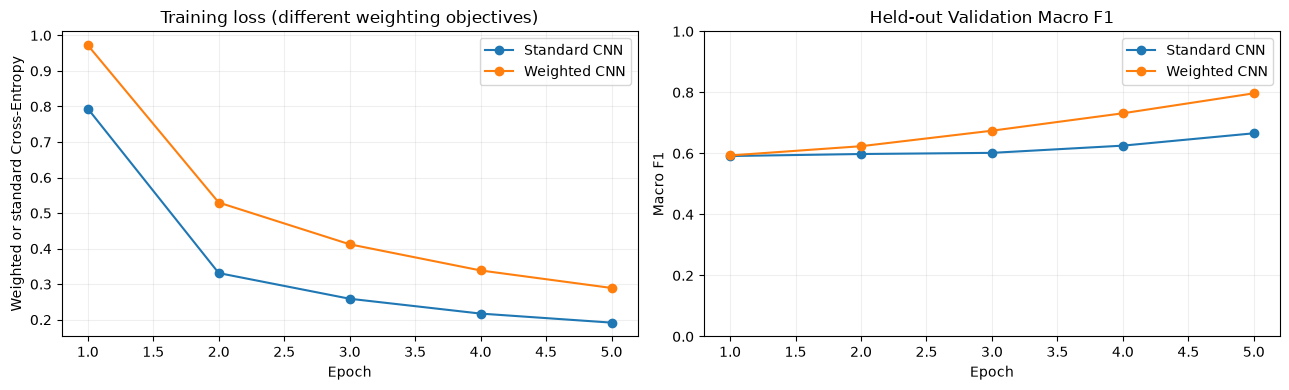

In [6]:
# ==================== 06. Compare training curves and held-out Validation results ====================
# 1. Follow the documented compare training curves and held-out validation results procedure with the established dataset and checks.

# Compare each last-epoch prediction on identical validation labels.
summary = pd.DataFrame([
    {"model": name,
     "macro_f1": f1_score(
         y_val, result["predicted"], labels=TASK_CLASSES,
         average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, result["predicted"]),
     "validation_windows": len(y_val)}
    for name, result in runs.items()
])
display(summary.round(4))

# Plot loss and validation Macro F1 with separate metric axes.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, result in runs.items():
    curve = result["history"]
    axes[0].plot(curve["epoch"], curve["train_loss"], marker="o", label=name)
    axes[1].plot(curve["epoch"], curve["validation_macro_f1"], marker="o", label=name)
axes[0].set(title="Training loss (different weighting objectives)",
            xlabel="Epoch", ylabel="Weighted or standard Cross-Entropy")
axes[1].set(title="Held-out Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

**07. Inspect minority-class performance and prediction errors**

Report all eight classes and make missing predictions visible, particularly Shuffling and stair activities.

,model,class,support,precision,recall,f1
0,Standard CNN,Walking,453,0.8848,0.9492,0.9159
1,Standard CNN,Running,78,0.9873,1.0000,0.9936
2,Standard CNN,Shuffling,15,0.0000,0.0000,0.0000
3,Standard CNN,Stairs ascending,30,1.0000,0.1000,0.1818
4,Standard CNN,Stairs descending,32,1.0000,0.1875,0.3158
5,Standard CNN,Standing,536,0.9348,0.9366,0.9357
6,Standard CNN,Sitting,1363,0.9749,0.9993,0.9870
7,Standard CNN,Lying,194,1.0000,0.9948,0.9974
8,Weighted CNN,Walking,453,0.9664,0.8896,0.9264
9,Weighted CNN,Running,78,1.0000,0.9744,0.9870


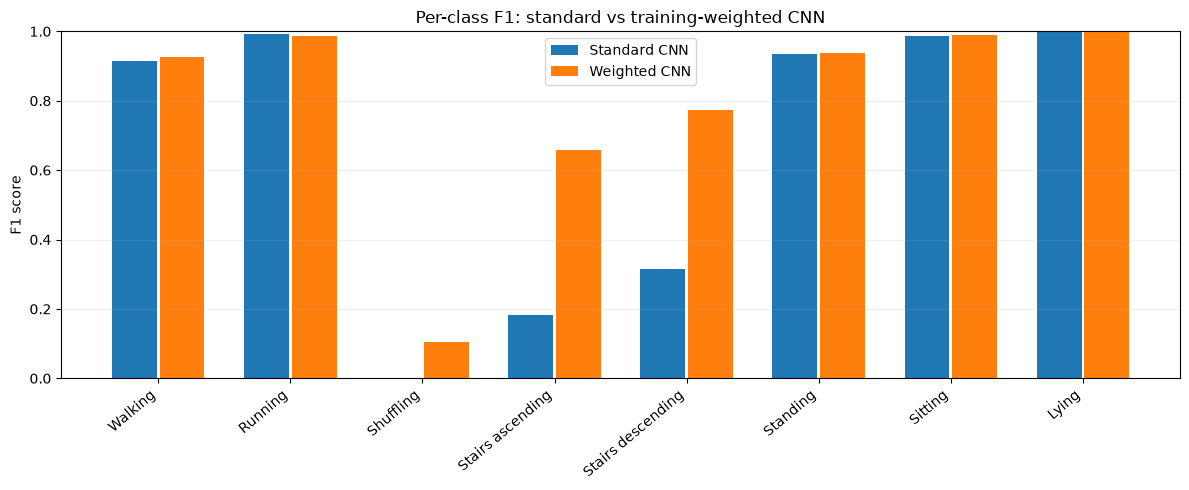

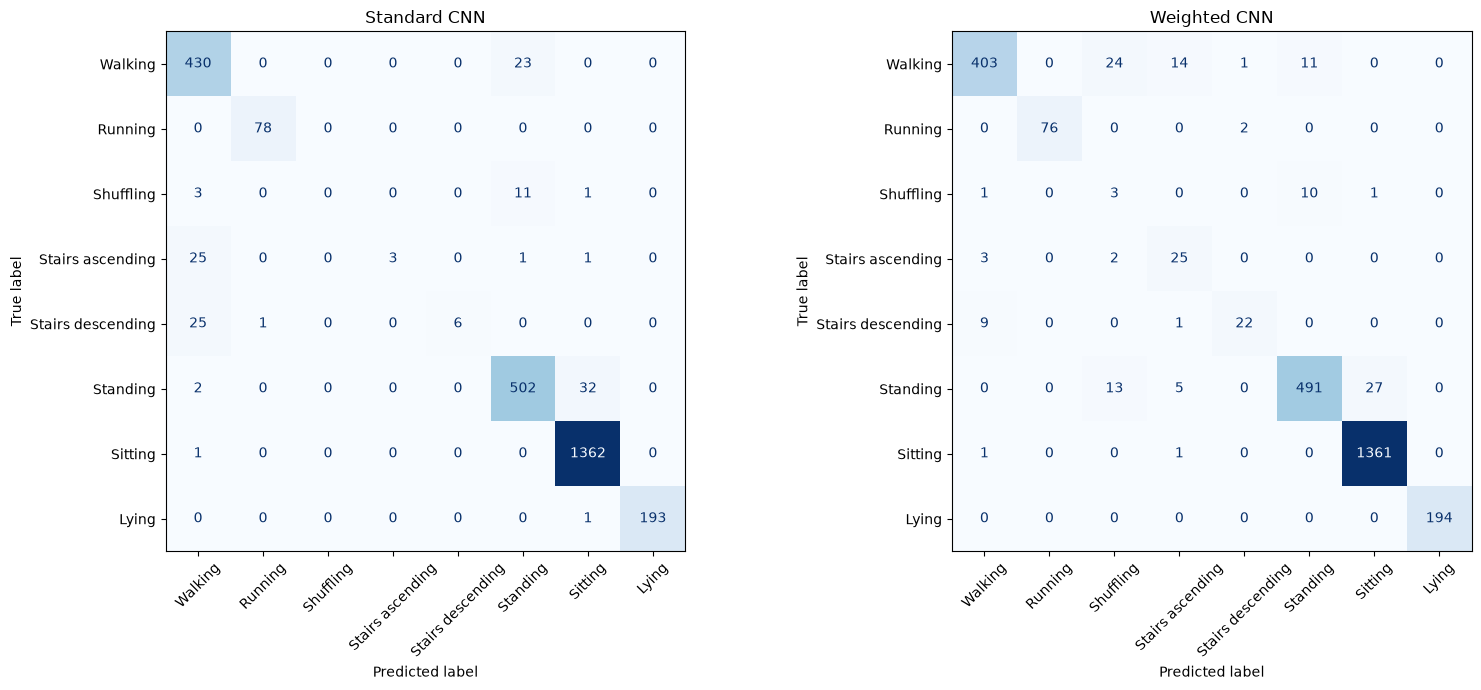

In [7]:
# ==================== 07. Inspect minority-class performance and prediction errors ====================
# 1. Follow the documented inspect minority-class performance and prediction errors procedure with the established dataset and checks.

# Show the exact precision, recall and F1 for both loss functions.
reports = []
for name, result in runs.items():
    report = classification_class_report(
        y_val, result["predicted"], classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    )
    report["model"] = name
    reports.append(report)
class_table = pd.concat(reports, ignore_index=True)
display(class_table[["model", "class", "support", "precision", "recall", "f1"]].round(4))

# Plot model F1 bars side-by-side for each activity.
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(TASK_CLASSES))
for i, name in enumerate(runs):
    values = class_table.loc[class_table["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 0.5) * 0.36, values, width=0.34, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES], rotation=40, ha="right")
ax.set(title="Per-class F1: standard vs training-weighted CNN",
       ylabel="F1 score", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

# Display both confusion matrices on the same true/predicted label axes.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, result) in zip(axes, runs.items()):
    matrix = confusion_matrix(y_val, result["predicted"], labels=TASK_CLASSES)
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()

**08. Check paired participant-level changes**

Every individual contributes one equal-weight comparison score; overlapping windows are not treated as independent study participants. This comparison is descriptive, not a statistical significance test.

,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3305,0.2318,0.0987
1,S012,0.8951,0.5911,0.3040
2,S019,0.8374,0.5911,0.2462
3,S022,0.9012,0.6290,0.2722
4,S036,0.4823,0.5745,-0.0922
5,S037,0.7780,0.7463,0.0318


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,6,0.1434,0.1725,5,1,0


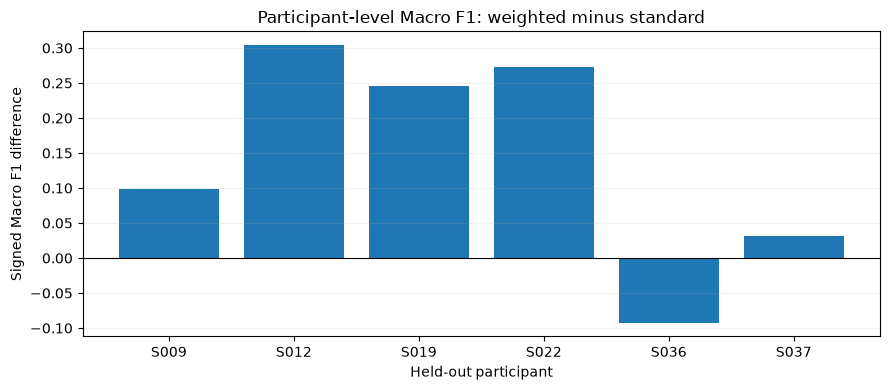

In [8]:
# ==================== 08. Check paired participant-level changes ====================
# 1. Follow the documented check paired participant-level changes procedure with the established dataset and checks.

# Compute fixed-eight-class Macro F1 for the same held-out participants.
individual_results = pd.concat([
    evaluate_predictions_by_subject(
        y_val, result["predicted"], val_subject_ids,
        TASK_CLASSES, model_name=name,
    )
    for name, result in runs.items()
], ignore_index=True)
paired, paired_summary = compare_models_by_subject(
    individual_results, model_a="Weighted CNN", model_b="Standard CNN",
    score_column="macro_f1_fixed_task",
)
display(paired.round(4))
display(pd.DataFrame([paired_summary]).round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Participant-level Macro F1: weighted minus standard",
       xlabel="Held-out participant", ylabel="Signed Macro F1 difference")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

**09. Research quality gate**

This is a controlled training-loss ablation on a previously inspected development Validation split. Findings are exploratory and should be followed by a broader group-CV design. Do not claim the held-out original Test has been independently evaluated.

In [9]:
# ==================== 09. Research quality gate ====================
# 1. Follow the documented research quality gate procedure with the established dataset and checks.

# Validate class specifications, identical predictions and subject boundaries.
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)
assert set(np.unique(y_train)) == set(TASK_CLASSES)
assert not (set(val_subject_ids) & RESERVED_TEST)
assert all(len(item["predicted"]) == len(y_val) for item in runs.values())
assert len(paired) == len(set(val_subject_ids))
assert summary["macro_f1"].between(0, 1).all()
print("Training-loss ablation quality gate: PASSED")
print("Reserved original Test loaded/scored: NO")
print("Independent validation of weight benefits: NOT ESTABLISHED")

Training-loss ablation quality gate: PASSED
Reserved original Test loaded/scored: NO
Independent validation of weight benefits: NOT ESTABLISHED
